### Lab 06 — Reinforcement learning

## Setup

Imports and paths. Notebooks run from `all_experiments/`, so the course folder is one level up; figures and tables go to `results/lab06/`.

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A — Tabular Q-learning in a 4×4 GridWorld

In [26]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

# Initialize and train Q-learning

In [27]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))       # explore: random move
    return int(np.argmax(Q[state]))                  # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

# Plot the Training Curve

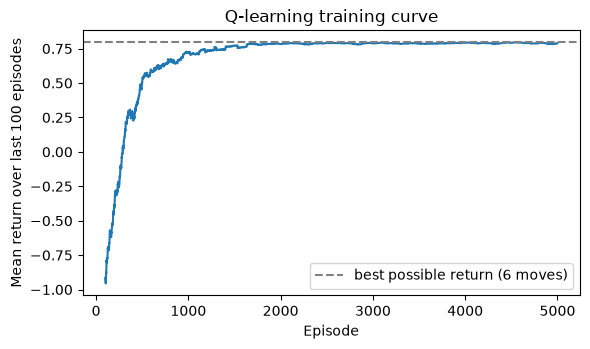

In [28]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "q_learning_training_curve.png", dpi=160, bbox_inches="tight")
plt.show()

The training curve shows that the agent's average return gradually improves over 5,000 episodes. Initially, the rewards fluctuate due to random exploration. As training progresses, the agent learns to select more effective actions, resulting in higher rewards. Eventually, the curve stabilizes near 0.80, indicating that the Q-learning algorithm has successfully learned an effective policy.

# Evaluate the Greedy Policy

In [29]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


The trained Q-learning agent achieved a 100% success rate across 200 evaluation episodes, with a mean return of 0.80. The learned starting action was down. These results indicate that the agent successfully learned an optimal route to reach the goal while avoiding the trap. The mean return of 0.80 confirms that the agent follows the shortest six-move route.

## Part B — The Q-table is the model: save it and read the policy

In [30]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)

Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


# Visualize the Greedy Policy and State Values

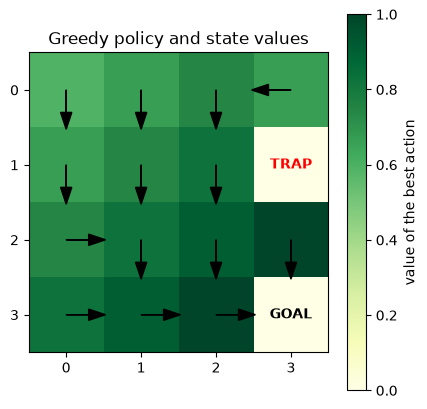

In [31]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.savefig(RESULTS / (re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_") + ".png"), dpi=160, bbox_inches="tight")
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")

## Try it yourself

Change one thing: the step cost, the trap location, the exploration schedule, or the discount factor. Write down what you expect the greedy policy to do differently before retraining, then check with `plot_policy`.

Attempt it in the cell below before reading the solution.

Change the step cost

In [32]:
def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""

    r, c = state
    dr, dc = ACTIONS[action]

    next_state = (
        min(max(r + dr, 0), ROWS - 1),
        min(max(c + dc, 0), COLS - 1)
    )

    if next_state == GOAL:
        return next_state, 1.0, True

    if next_state == TRAP:
        return next_state, -1.0, True

    return next_state, -0.10, False  # Changed from -0.04

Predict the policy change

Increasing the movement penalty from -0.04 to -0.10 is expected to encourage the agent to reach the goal using fewer movements to minimise the accumulated penalty.

Retrain the Q-learning agent

In [33]:
# Reset Q-table and exploration rate
rng = np.random.default_rng(42)

Q = np.zeros((ROWS, COLS, len(ACTIONS)))

alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

training_returns = []

# Train for 5,000 episodes
for episode in range(5000):

    state, episode_return = START, 0.0

    for _ in range(100):

        action = choose_action(state)

        next_state, reward, done = step(state, action)

        episode_return += reward

        target = reward if done else reward + gamma * np.max(Q[next_state])

        Q[state][action] += alpha * (target - Q[state][action])

        state = next_state

        if done:
            break

    training_returns.append(episode_return)

    epsilon = max(min_epsilon, epsilon * 0.9985)

print("Experimental training completed!")

Experimental training completed!


Visualize the new policy

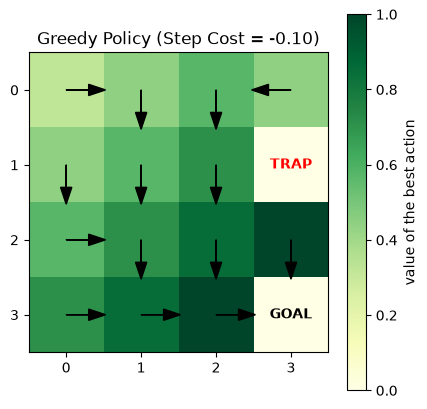

In [34]:
plot_policy(Q, "Greedy Policy (Step Cost = -0.10)")

The step cost was changed from -0.04 to -0.10 to investigate its effect on the Q-learning agent's policy. The agent was retrained for 5,000 episodes using the same learning rate, discount factor and exploration schedule.

The experimental visualization shows that the agent continues to navigate towards the goal while avoiding the trap. The optimal route remains six moves, but the expected return decreases from 0.80 to 0.50 due to the increased movement penalty.

This experiment demonstrates how changing the reward structure affects the Q-values and expected returns of the learned policy.